# Early Prediction of Student Academic Risk from Micro-Temporal VLE Behaviour (OULAD)

Revised analysis pipeline. Changes with respect to the first version of this notebook:

1. **Unit of analysis = enrolment** (`id_student`, `code_module`, `code_presentation`), not student. The earlier
   student-level merge pooled clicks across different modules and kept duplicate rows with identical features but
   different labels.
2. **Genuinely early features.** All features are computed only from data observed up to a cutoff week, and students
   who had already unregistered by the cutoff are removed from that cutoff's population. The earlier version used the
   whole presentation, so `active_days` partly encoded the outcome (students who withdrew stop logging in).
3. **No misleading imputation.** Students with no submissions get a *missing* latency (not 0 = "on time"), and a new
   `missed_submissions` feature counts coursework due by the cutoff but not submitted.
4. **Engagement slope / inconsistency over a zero-filled weekly series**, so inactive weeks count as zero activity
   instead of being skipped.
5. **Baselines, tuning and honest validation:** Logistic Regression, Random Forest, XGBoost and LightGBM, each tuned with
   student-grouped 5-fold CV on past presentations (2013B, 2013J, 2014B) and evaluated on a later, unseen presentation
   (2014J). Test AUCs carry 95% bootstrap confidence intervals, and model differences are tested with paired bootstrap.
   Decision thresholds are chosen on out-of-fold training predictions (max F1), never on the test set.
6. **Ablation** against a demographic-only model, and a **sensitivity analysis** on Fail vs Pass only (withdrawals
   excluded).

In [1]:
import os, json, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display
from scipy.stats import loguniform, randint, uniform
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score,
                             recall_score, f1_score, roc_curve, precision_recall_curve)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import shap

warnings.filterwarnings('ignore')
os.environ['PYTHONWARNINGS'] = 'ignore'   # also silences parallel CV workers
SEED = 42
np.random.seed(SEED)

DATA_DIR = 'Dataset' if os.path.exists(os.path.join('Dataset', 'studentInfo.csv')) else 'oulad_data'
FIG_DIR, RES_DIR = 'figures', 'results'
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

KEY = ['id_student', 'code_module', 'code_presentation']
CUTOFF_WEEKS = [2, 4, 6, 9, 12, 16, 20]   # weeks of data observed (day 0 = module start)
PRIMARY_WEEK = 9                         # day 62: first week by which every module has had coursework due (GGG: day 61)
FULL_WEEKS = 39                          # retrospective reference: whole presentation (longest = 269 days)
TRAIN_PRES = ['2013B', '2013J', '2014B'] # past presentations -> model development
TEST_PRES = ['2014J']                    # later, unseen presentation -> temporal test set
N_ITER, N_FOLDS, N_BOOT = 15, 5, 1000

## 1. Load OULAD

In [2]:
student_info = pd.read_csv(os.path.join(DATA_DIR, 'studentInfo.csv'))
student_reg = pd.read_csv(os.path.join(DATA_DIR, 'studentRegistration.csv'))
assessments = pd.read_csv(os.path.join(DATA_DIR, 'assessments.csv'))
student_assessment = pd.read_csv(os.path.join(DATA_DIR, 'studentAssessment.csv'))
courses = pd.read_csv(os.path.join(DATA_DIR, 'courses.csv'))
student_vle = pd.read_csv(
    os.path.join(DATA_DIR, 'studentVle.csv'),
    usecols=['code_module', 'code_presentation', 'id_student', 'date', 'sum_click'],
    dtype={'code_module': 'category', 'code_presentation': 'category',
           'id_student': 'int32', 'date': 'int16', 'sum_click': 'int32'})

print(f"studentInfo rows: {len(student_info):,} | VLE log rows: {len(student_vle):,} | "
      f"assessment submissions: {len(student_assessment):,}")
print(f"Presentation length (days): mean {courses.module_presentation_length.mean():.0f}, "
      f"range {courses.module_presentation_length.min()}-{courses.module_presentation_length.max()}")

studentInfo rows: 32,593 | VLE log rows: 10,655,280 | assessment submissions: 173,912
Presentation length (days): mean 256, range 234-269


## 2. Enrolment-level table and target

Target: $y = 1$ (at risk) if `final_result` $\in$ {Fail, Withdrawn}, $y = 0$ if $\in$ {Pass, Distinction}.
This is an **academic-outcome** label; OULAD contains no psychological measures.

In [3]:
enrol = student_info.merge(student_reg[KEY + ['date_registration', 'date_unregistration']], on=KEY, how='left')
enrol['risk_label'] = enrol['final_result'].isin(['Fail', 'Withdrawn']).astype(int)
enrol['eid'] = np.arange(len(enrol))
enrol['split'] = np.where(enrol['code_presentation'].isin(TEST_PRES), 'test', 'train')

per_student = enrol.groupby('id_student').agg(n=('eid', 'size'), n_labels=('risk_label', 'nunique'))
print(f"Enrolments: {len(enrol):,} | unique students: {len(per_student):,} | "
      f"students with >1 enrolment: {(per_student.n > 1).sum():,} | "
      f"students whose enrolments have conflicting labels: {(per_student.n_labels > 1).sum():,}")
print()
print(enrol['final_result'].value_counts().to_string())
print()
display(enrol.groupby('split').agg(enrolments=('eid', 'size'), students=('id_student', 'nunique'),
                                   at_risk_rate=('risk_label', 'mean')).round(3))

Enrolments: 32,593 | unique students: 28,785 | students with >1 enrolment: 3,538 | students whose enrolments have conflicting labels: 1,168

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024



,enrolments,students,at_risk_rate
split,,,
test,11260,10670,0.515
train,21333,19720,0.535


## 3. Pre-aggregate raw logs

In [4]:
# Daily clicks per enrolment
daily = student_vle.groupby(KEY + ['date'], observed=True)['sum_click'].sum().reset_index()
for c in ['code_module', 'code_presentation']:
    daily[c] = daily[c].astype(str)
daily = daily.merge(enrol[KEY + ['eid']], on=KEY, how='inner')
daily_eid = daily['eid'].to_numpy()
daily_date = daily['date'].to_numpy().astype(int)
daily_clicks = daily['sum_click'].to_numpy().astype(float)
del student_vle

# Coursework (TMA/CMA) with a known due date; the final exam falls after every early cutoff
coursework = assessments[(assessments.assessment_type != 'Exam') & assessments.date.notna()][
    ['id_assessment', 'code_module', 'code_presentation', 'date']]
subs = (student_assessment.merge(coursework, on='id_assessment', how='inner')
        .merge(enrol[KEY + ['eid']], on=KEY, how='inner'))
subs['latency'] = subs['date_submitted'] - subs['date']   # > 0 means late

# Static demographic baseline features (one-hot); names sanitised for XGBoost/LightGBM
DEMO_CAT = ['gender', 'region', 'highest_education', 'imd_band', 'age_band', 'disability']
DEMO_NUM = ['num_of_prev_attempts', 'studied_credits']
demo = pd.get_dummies(enrol[DEMO_CAT].fillna('Unknown'), dtype=float)
demo[DEMO_NUM] = enrol[DEMO_NUM].astype(float)
demo.columns = [re.sub(r'[^0-9A-Za-z_]+', '_', c) for c in demo.columns]
demo.index = enrol['eid']
DEMO = list(demo.columns)

print(f"Daily activity rows: {len(daily):,} | coursework submissions: {len(subs):,} | demographic columns: {len(DEMO)}")

Daily activity rows: 1,808,119 | coursework submissions: 168,953 | demographic columns: 38


## 4. Micro-temporal behavioural features at a cutoff

For cutoff week $w$ the last observed day is $d = 7w - 1$. Only logs with `date` $\le d$ and submissions with
`date_submitted` $\le d$ are used.

| Feature | Definition |
|---|---|
| `avg_latency` | mean of $\Delta t_i = t^{sub}_i - t^{due}_i$ over submissions made by $d$ (missing if none) |
| `late_submissions` | number of submissions made by $d$ with $\Delta t_i > 0$ |
| `missed_submissions` | coursework due by $d$ and not submitted by $d$ |
| `inconsistency_index` | coefficient of variation of weekly clicks over weeks $0..w-1$ (zero-filled) |
| `total_clicks` | total clicks up to $d$ (including pre-start activity) |
| `active_days` | distinct days with any VLE activity up to $d$ |
| `engagement_slope` | OLS slope of weekly clicks over weeks $0..w-1$ (zero-filled), clicks/week |
| `days_since_last_activity` | $d$ minus the last active day (missing if never active) |

In [5]:
BEHAV = ['avg_latency', 'late_submissions', 'missed_submissions', 'inconsistency_index',
         'total_clicks', 'active_days', 'engagement_slope', 'days_since_last_activity']
PRETTY = {'avg_latency': 'Avg. submission latency', 'late_submissions': 'Late submissions',
          'missed_submissions': 'Missed submissions', 'inconsistency_index': 'Inconsistency index',
          'total_clicks': 'Total clicks', 'active_days': 'Active days',
          'engagement_slope': 'Engagement slope', 'days_since_last_activity': 'Days since last activity'}
N_ENROL = len(enrol)
_feature_cache = {}

def build_features(week):
    if week in _feature_cache:
        return _feature_cache[week]
    d = 7 * week - 1
    m = daily_date <= d
    e, t, c = daily_eid[m], daily_date[m], daily_clicks[m]

    total_clicks = np.bincount(e, weights=c, minlength=N_ENROL)
    active_days = np.bincount(e, minlength=N_ENROL).astype(float)
    last_day = np.full(N_ENROL, -np.inf)
    np.maximum.at(last_day, e, t)
    days_since = np.where(np.isfinite(last_day), d - last_day, np.nan)

    weekly = np.zeros((N_ENROL, week))
    in_course = t >= 0
    np.add.at(weekly, (e[in_course], t[in_course] // 7), c[in_course])
    w_mean, w_std = weekly.mean(axis=1), weekly.std(axis=1)
    inconsistency = np.divide(w_std, w_mean, out=np.zeros(N_ENROL), where=w_mean > 0)
    tc = np.arange(week) - (week - 1) / 2
    slope = weekly @ tc / (tc ** 2).sum()

    seen = subs[subs.date_submitted <= d]
    timed = seen[seen.is_banked == 0]   # banked results carry over from an earlier presentation
    avg_latency = timed.groupby('eid')['latency'].mean().reindex(range(N_ENROL)).to_numpy()
    late = (timed.latency > 0).groupby(timed.eid).sum().reindex(range(N_ENROL), fill_value=0).to_numpy()
    due_by_d = coursework[coursework.date <= d].groupby(['code_module', 'code_presentation']).size().rename('n_due')
    n_due = enrol[['code_module', 'code_presentation']].merge(
        due_by_d.reset_index(), on=['code_module', 'code_presentation'], how='left')['n_due'].fillna(0).to_numpy()
    submitted_due = seen[seen.date <= d].groupby('eid').size().reindex(range(N_ENROL), fill_value=0).to_numpy()
    missed = np.clip(n_due - submitted_due, 0, None)

    X = pd.DataFrame({'avg_latency': avg_latency, 'late_submissions': late, 'missed_submissions': missed,
                      'inconsistency_index': inconsistency, 'total_clicks': total_clicks,
                      'active_days': active_days, 'engagement_slope': slope,
                      'days_since_last_activity': days_since}, index=enrol['eid']).astype(float)
    _feature_cache[week] = X
    return X

def population_mask(week, label_mode='risk', retrospective=False):
    # Enrolments still registered at the end of the cutoff week (withdrawals before the cutoff are already known)
    d = 7 * week - 1
    still_enrolled = enrol.date_unregistration.isna() | (enrol.date_unregistration > d)
    mask = pd.Series(True, index=enrol.index) if retrospective else still_enrolled
    if label_mode == 'fail_vs_pass':
        mask &= enrol.final_result != 'Withdrawn'
    return mask.to_numpy()

def labels(label_mode='risk'):
    if label_mode == 'fail_vs_pass':
        return (enrol.final_result == 'Fail').astype(int).to_numpy()
    return enrol.risk_label.to_numpy()

display(build_features(PRIMARY_WEEK).describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
avg_latency,25027.0,-12.21,32.04,-236.00,-3.00,-0.67,1.00,41.00
late_submissions,32593.0,0.40,0.65,0.00,0.00,0.00,1.00,4.00
missed_submissions,32593.0,0.61,0.96,0.00,0.00,0.00,1.00,4.00
inconsistency_index,32593.0,1.02,0.71,0.00,0.57,0.92,1.41,2.83
total_clicks,32593.0,498.01,667.57,0.00,78.00,284.00,655.00,11208.00
active_days,32593.0,22.19,18.63,0.00,7.00,18.00,34.00,88.00
engagement_slope,32593.0,-4.20,9.73,-296.35,-6.70,-1.90,0.00,232.53
days_since_last_activity,29119.0,11.17,17.45,0.00,1.00,3.00,12.00,87.00


### Population at each cutoff

In [6]:
mean_len = courses.module_presentation_length.mean()
rows = []
for w in CUTOFF_WEEKS:
    m = population_mask(w)
    rows.append({'cutoff_week': w, 'last_day': 7 * w - 1, 'pct_of_course': round(100 * (7 * w) / mean_len, 1),
                 'already_withdrawn_excluded': int((~m).sum()),
                 'train_n': int((m & (enrol.split == 'train')).sum()), 'test_n': int((m & (enrol.split == 'test')).sum()),
                 'at_risk_rate': round(enrol.risk_label[m].mean(), 3)})
population = pd.DataFrame(rows)
population.to_csv(os.path.join(RES_DIR, 'population_by_cutoff.csv'), index=False)
display(population)

,cutoff_week,last_day,pct_of_course,already_withdrawn_excluded,train_n,test_n,at_risk_rate
0,2,13,5.5,4465,18765,9363,0.453
1,4,27,11.0,5040,18334,9219,0.442
2,6,41,16.4,5559,17989,9045,0.431
3,9,62,24.7,6291,17508,8794,0.415
4,12,83,32.9,6860,17161,8572,0.402
5,16,111,43.8,7652,16621,8320,0.383
6,20,139,54.8,8299,16186,8108,0.367


## 5. Models, tuning and evaluation

In [7]:
def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))

def model_zoo():
    imputer = lambda: SimpleImputer(strategy='median', add_indicator=True)
    return {
        'Logistic Regression': (
            Pipeline([('imp', imputer()), ('log', FunctionTransformer(signed_log1p)),
                      ('sc', StandardScaler()), ('clf', LogisticRegression(max_iter=5000))]),
            {'clf__C': loguniform(1e-3, 1e2)}),
        'Random Forest': (
            Pipeline([('imp', imputer()), ('clf', RandomForestClassifier(random_state=SEED, n_jobs=1))]),
            {'clf__n_estimators': [200, 300], 'clf__max_depth': [8, 12, 16, None],
             'clf__min_samples_leaf': [5, 10, 20, 50], 'clf__max_features': ['sqrt', 0.5, 0.8]}),
        'XGBoost': (
            XGBClassifier(tree_method='hist', eval_metric='logloss', random_state=SEED, n_jobs=1),
            {'n_estimators': randint(100, 600), 'max_depth': randint(2, 8), 'learning_rate': loguniform(0.01, 0.2),
             'subsample': uniform(0.6, 0.4), 'colsample_bytree': uniform(0.6, 0.4), 'min_child_weight': randint(1, 20)}),
        'LightGBM': (
            LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1),
            {'n_estimators': randint(100, 600), 'num_leaves': randint(8, 64), 'learning_rate': loguniform(0.01, 0.2),
             'subsample': uniform(0.6, 0.4), 'subsample_freq': [1], 'colsample_bytree': uniform(0.6, 0.4),
             'min_child_samples': randint(10, 100)}),
    }

FEATURE_SETS = {'Behavioral': BEHAV, 'Demographic': DEMO, 'Behavioral + Demographic': BEHAV + DEMO}
EXPERIMENTS = ([('Behavioral', m) for m in ['Logistic Regression', 'Random Forest', 'XGBoost', 'LightGBM']]
               + [('Demographic', 'Logistic Regression'), ('Demographic', 'XGBoost'),
                  ('Behavioral + Demographic', 'XGBoost')])

def f1_threshold(y, p):
    # Decision threshold maximising F1 on out-of-fold training predictions (the test set is never used)
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[np.argmax(f1)])

def run(week, feature_set, model_name, label_mode='risk', retrospective=False):
    X = build_features(week).join(demo)[FEATURE_SETS[feature_set]]
    y, mask = labels(label_mode), population_mask(week, label_mode, retrospective)
    tr, te = mask & (enrol.split == 'train').to_numpy(), mask & (enrol.split == 'test').to_numpy()
    groups = enrol.id_student.to_numpy()[tr]
    cv = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED)
    est, dist = model_zoo()[model_name]
    search = RandomizedSearchCV(est, dist, n_iter=N_ITER, scoring='roc_auc', n_jobs=-1, random_state=SEED,
                                cv=cv, refit=True)
    search.fit(X[tr], y[tr], groups=groups)
    oof = cross_val_predict(clone(search.best_estimator_), X[tr], y[tr], groups=groups, cv=cv,
                            method='predict_proba', n_jobs=-1)[:, 1]
    threshold = f1_threshold(y[tr], oof)
    p = search.predict_proba(X[te])[:, 1]
    pred = (p >= threshold).astype(int)
    yt = y[te]
    row = {'cutoff_week': 'full' if retrospective else week, 'label': label_mode, 'feature_set': feature_set,
           'model': model_name, 'n_train': int(tr.sum()), 'n_test': int(te.sum()), 'threshold': threshold,
           'cv_auc_mean': search.best_score_, 'cv_auc_std': search.cv_results_['std_test_score'][search.best_index_],
           'test_auc': roc_auc_score(yt, p), 'test_pr_auc': average_precision_score(yt, p),
           'accuracy': accuracy_score(yt, pred), 'precision': precision_score(yt, pred),
           'recall': recall_score(yt, pred), 'f1': f1_score(yt, pred),
           'best_params': json.dumps({k: (v.item() if hasattr(v, 'item') else v)
                                      for k, v in search.best_params_.items()})}
    return row, {'y': yt, 'p': p, 'model': search.best_estimator_, 'X_test': X[te]}

In [8]:
results, store = [], {}
t0 = time.time()
for w in CUTOFF_WEEKS:
    for fs, mn in EXPERIMENTS:
        row, out = run(w, fs, mn)
        results.append(row); store[(w, fs, mn)] = out
    print(f"week {w:>2} done ({time.time() - t0:.0f}s)")

# Retrospective reference: whole presentation, everyone included (the setting of the first version)
for mn in ['Logistic Regression', 'XGBoost']:
    row, out = run(FULL_WEEKS, 'Behavioral', mn, retrospective=True)
    results.append(row); store[('full', 'Behavioral', mn)] = out
print(f"full-course reference done ({time.time() - t0:.0f}s)")

week  2 done (465s)


week  4 done (983s)


week  6 done (1509s)


week  9 done (1986s)


week 12 done (2445s)


week 16 done (2845s)


week 20 done (3044s)


full-course reference done (3096s)


### Bootstrap confidence intervals and paired comparisons (test set)

In [9]:
rng = np.random.default_rng(SEED)
REF = ('Behavioral', 'XGBoost')
boot_cols = {}
for w in CUTOFF_WEEKS + ['full']:
    keys = [k for k in store if k[0] == w]
    n = len(store[keys[0]]['y'])
    idx = rng.integers(0, n, size=(N_BOOT, n))
    aucs = {}
    for k in keys:
        y, p = store[k]['y'], store[k]['p']
        aucs[k] = np.array([roc_auc_score(y[i], p[i]) for i in idx])
    for k in keys:
        lo, hi = np.percentile(aucs[k], [2.5, 97.5])
        entry = {'auc_ci_low': lo, 'auc_ci_high': hi}
        ref = (w,) + REF
        if ref in aucs and k != ref:
            diff = aucs[k] - aucs[ref]
            entry.update({'delta_auc_vs_xgb': diff.mean(),
                          'delta_ci_low': np.percentile(diff, 2.5), 'delta_ci_high': np.percentile(diff, 97.5),
                          'p_vs_xgb': min(1.0, 2 * min((diff <= 0).mean(), (diff >= 0).mean()))})
        boot_cols[k] = entry

res = pd.DataFrame(results)
boot = pd.DataFrame([{'cutoff_week': k[0], 'feature_set': k[1], 'model': k[2], **v} for k, v in boot_cols.items()])
res = res.merge(boot, on=['cutoff_week', 'feature_set', 'model'], how='left')
res.to_csv(os.path.join(RES_DIR, 'model_comparison_by_cutoff.csv'), index=False)

def fmt_table(df):
    out = df[['feature_set', 'model', 'cv_auc_mean', 'cv_auc_std', 'test_auc', 'auc_ci_low', 'auc_ci_high',
              'test_pr_auc', 'threshold', 'accuracy', 'precision', 'recall', 'f1']].copy()
    out['CV AUC'] = out.cv_auc_mean.map('{:.3f}'.format) + ' ± ' + out.cv_auc_std.map('{:.3f}'.format)
    out['Test AUC [95% CI]'] = (out.test_auc.map('{:.3f}'.format) + ' [' + out.auc_ci_low.map('{:.3f}'.format)
                                + ', ' + out.auc_ci_high.map('{:.3f}'.format) + ']')
    return out[['feature_set', 'model', 'CV AUC', 'Test AUC [95% CI]', 'test_pr_auc', 'threshold', 'accuracy',
                'precision', 'recall', 'f1']].round(3)

primary = res[res.cutoff_week == PRIMARY_WEEK]
print(f"=== Primary early-warning cutoff: week {PRIMARY_WEEK} (day {7 * PRIMARY_WEEK - 1}), temporal test on {TEST_PRES} ===")
display(fmt_table(primary))
fmt_table(primary).to_csv(os.path.join(RES_DIR, f'table_week{PRIMARY_WEEK}.csv'), index=False)
display(primary[['feature_set', 'model', 'delta_auc_vs_xgb', 'delta_ci_low', 'delta_ci_high', 'p_vs_xgb']]
        .dropna().round(4))

=== Primary early-warning cutoff: week 9 (day 62), temporal test on ['2014J'] ===


,feature_set,model,CV AUC,Test AUC [95% CI],test_pr_auc,threshold,accuracy,precision,recall,f1
21,Behavioral,Logistic Regression,0.769 ± 0.003,"0.757 [0.746, 0.767]",0.708,0.320,0.650,0.527,0.760,0.622
22,Behavioral,Random Forest,0.787 ± 0.005,"0.776 [0.765, 0.785]",0.729,0.361,0.684,0.566,0.717,0.633
23,Behavioral,XGBoost,0.791 ± 0.006,"0.774 [0.764, 0.784]",0.722,0.358,0.686,0.568,0.720,0.635
24,Behavioral,LightGBM,0.790 ± 0.006,"0.774 [0.764, 0.784]",0.724,0.367,0.686,0.569,0.716,0.634
25,Demographic,Logistic Regression,0.644 ± 0.006,"0.626 [0.614, 0.637]",0.499,0.329,0.492,0.417,0.847,0.559
26,Demographic,XGBoost,0.643 ± 0.005,"0.626 [0.615, 0.637]",0.497,0.312,0.458,0.405,0.911,0.561
27,Behavioral + Demographic,XGBoost,0.806 ± 0.004,"0.790 [0.781, 0.799]",0.741,0.363,0.700,0.582,0.746,0.654


,feature_set,model,delta_auc_vs_xgb,delta_ci_low,delta_ci_high,p_vs_xgb
21,Behavioral,Logistic Regression,-0.0169,-0.0217,-0.0117,0.000
22,Behavioral,Random Forest,0.0015,-0.0009,0.0040,0.288
24,Behavioral,LightGBM,-0.0003,-0.0016,0.0012,0.748
25,Demographic,Logistic Regression,-0.1482,-0.1638,-0.1329,0.000
26,Demographic,XGBoost,-0.1482,-0.1636,-0.1335,0.000
27,Behavioral + Demographic,XGBoost,0.0161,0.0113,0.0208,0.000


In [10]:
# How much of the first version's AUC came from post-outcome information?
beh_xgb = res[(res.feature_set == 'Behavioral') & (res.model == 'XGBoost')].copy()
display(beh_xgb[['cutoff_week', 'n_train', 'n_test', 'test_auc', 'auc_ci_low', 'auc_ci_high', 'f1']].round(3))
display(res[(res.feature_set == 'Behavioral')].pivot(index='cutoff_week', columns='model', values='test_auc')
        .reindex(CUTOFF_WEEKS + ['full']).round(3))
display(res[res.model == 'XGBoost'].pivot(index='cutoff_week', columns='feature_set', values='test_auc')
        .reindex(CUTOFF_WEEKS + ['full']).round(3))

,cutoff_week,n_train,n_test,test_auc,auc_ci_low,auc_ci_high,f1
2,2,18765,9363,0.676,0.665,0.687,0.615
9,4,18334,9219,0.714,0.704,0.724,0.620
16,6,17989,9045,0.734,0.724,0.745,0.622
23,9,17508,8794,0.774,0.764,0.784,0.635
30,12,17161,8572,0.780,0.770,0.790,0.625
37,16,16621,8320,0.824,0.814,0.833,0.658
44,20,16186,8108,0.845,0.835,0.854,0.674
50,full,21333,11260,0.968,0.965,0.971,0.926


model,LightGBM,Logistic Regression,Random Forest,XGBoost
cutoff_week,,,,
2,0.674,0.675,0.675,0.676
4,0.716,0.705,0.717,0.714
6,0.733,0.720,0.735,0.734
9,0.774,0.757,0.776,0.774
12,0.778,0.756,0.780,0.780
16,0.824,0.806,0.823,0.824
20,0.843,0.834,0.846,0.845
full,NaN,0.960,NaN,0.968


feature_set,Behavioral,Behavioral + Demographic,Demographic
cutoff_week,,,
2,0.676,0.709,0.622
4,0.714,0.748,0.624
6,0.734,0.758,0.625
9,0.774,0.790,0.626
12,0.780,0.793,0.626
16,0.824,0.832,0.629
20,0.845,0.853,0.634
full,0.968,NaN,NaN


## 6. Figures

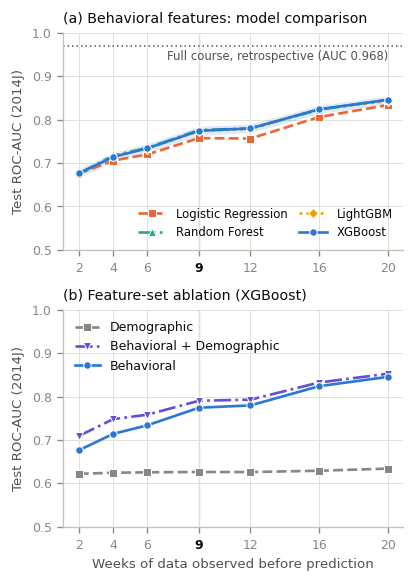

In [11]:
# Figure styling: light print surface, recessive axes, categorical hues in fixed order
INK, INK2, MUTED, GRID, AXIS = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
C = {'XGBoost': '#2a78d6', 'Logistic Regression': '#eb6834', 'Random Forest': '#1baf7a', 'LightGBM': '#eda100'}
MARK = {'XGBoost': 'o', 'Logistic Regression': 's', 'Random Forest': '^', 'LightGBM': 'D'}
DASH = {'XGBoost': '-', 'Logistic Regression': '--', 'Random Forest': '-.', 'LightGBM': ':'}
FS_STYLE = {'Behavioral': ('#2a78d6', 'o', '-'), 'Behavioral + Demographic': ('#6250d6', 'v', '-.'),
            'Demographic': (MUTED, 's', '--')}
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 8, 'axes.titlesize': 8.5, 'axes.labelsize': 8,
    'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5, 'legend.fontsize': 7.5, 'legend.frameon': False,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'lines.linewidth': 1.6, 'lines.markersize': 4.5, 'figure.dpi': 120, 'savefig.dpi': 300,
    'savefig.bbox': 'tight', 'figure.facecolor': 'white', 'axes.facecolor': 'white'})

def series(fs, mn):
    s = res[(res.feature_set == fs) & (res.model == mn) & (res.cutoff_week != 'full')]
    return s.set_index('cutoff_week').reindex(CUTOFF_WEEKS)

full_auc = res[(res.cutoff_week == 'full') & (res.feature_set == 'Behavioral') & (res.model == 'XGBoost')].test_auc.iloc[0]
fig, axes = plt.subplots(2, 1, figsize=(3.5, 4.9), sharex=True)   # stacked to fit one IEEE column
ax = axes[0]
for mn in ['Logistic Regression', 'Random Forest', 'LightGBM', 'XGBoost']:
    s = series('Behavioral', mn)
    if mn == 'XGBoost':
        ax.fill_between(CUTOFF_WEEKS, s.auc_ci_low, s.auc_ci_high, color=C[mn], alpha=0.15, lw=0)
    ax.plot(CUTOFF_WEEKS, s.test_auc, color=C[mn], marker=MARK[mn], ls=DASH[mn], label=mn,
            markeredgecolor='white', markeredgewidth=0.6)
ax.axhline(full_auc, color=INK2, lw=0.9, ls=(0, (1, 2)))
ax.text(CUTOFF_WEEKS[-1], full_auc - 0.008, f'Full course, retrospective (AUC {full_auc:.3f})',
        ha='right', va='top', color=INK2, fontsize=7)
ax.set_title('(a) Behavioral features: model comparison', loc='left')
ax.legend(loc='lower right', ncol=2, fontsize=7, columnspacing=1.0, handlelength=2.4)

ax = axes[1]
for fs in ['Demographic', 'Behavioral + Demographic', 'Behavioral']:
    col, mk, ls = FS_STYLE[fs]
    s = series(fs, 'XGBoost')
    ax.plot(CUTOFF_WEEKS, s.test_auc, color=col, marker=mk, ls=ls, label=fs,
            markeredgecolor='white', markeredgewidth=0.6)
ax.set_title('(b) Feature-set ablation (XGBoost)', loc='left')
ax.legend(loc='upper left')

for ax in axes:
    ax.axvline(PRIMARY_WEEK, color=AXIS, lw=0.8, zorder=0)   # primary early-warning cutoff
    ax.set_xticks(CUTOFF_WEEKS)
    ax.tick_params(labelbottom=True)
    for lbl, w in zip(ax.get_xticklabels(), CUTOFF_WEEKS):
        if w == PRIMARY_WEEK:
            lbl.set_fontweight('bold'); lbl.set_color(INK)
    ax.set_ylim(0.5, 1.0)
    ax.set_ylabel('Test ROC-AUC (2014J)')
axes[1].set_xlabel('Weeks of data observed before prediction')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'fig_auc_vs_cutoff.png'))
plt.show()

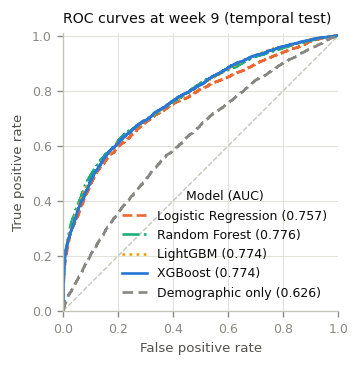

In [12]:
fig, ax = plt.subplots(figsize=(3.5, 3.1))
ax.plot([0, 1], [0, 1], color=AXIS, lw=0.8, ls='--')
for mn in ['Logistic Regression', 'Random Forest', 'LightGBM', 'XGBoost']:
    o = store[(PRIMARY_WEEK, 'Behavioral', mn)]
    fpr, tpr, _ = roc_curve(o['y'], o['p'])
    ax.plot(fpr, tpr, color=C[mn], ls=DASH[mn], label=f"{mn} ({roc_auc_score(o['y'], o['p']):.3f})")
o = store[(PRIMARY_WEEK, 'Demographic', 'XGBoost')]
fpr, tpr, _ = roc_curve(o['y'], o['p'])
ax.plot(fpr, tpr, color=MUTED, ls=(0, (4, 2)), label=f"Demographic only ({roc_auc_score(o['y'], o['p']):.3f})")
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
ax.set_title(f'ROC curves at week {PRIMARY_WEEK} (temporal test)', loc='left')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01); ax.set_aspect('equal')
ax.legend(loc='lower right', title='Model (AUC)', title_fontsize=7.5)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, f'fig_roc_week{PRIMARY_WEEK}.png'))
plt.show()

## 7. Explainability (SHAP, XGBoost, behavioural features)

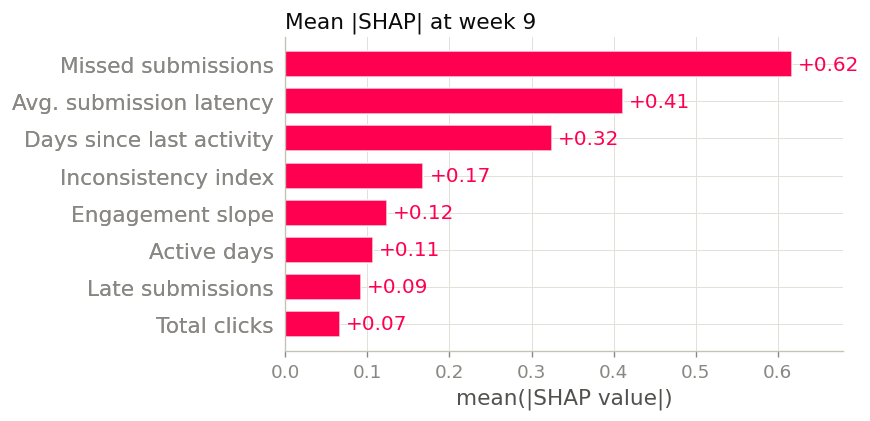

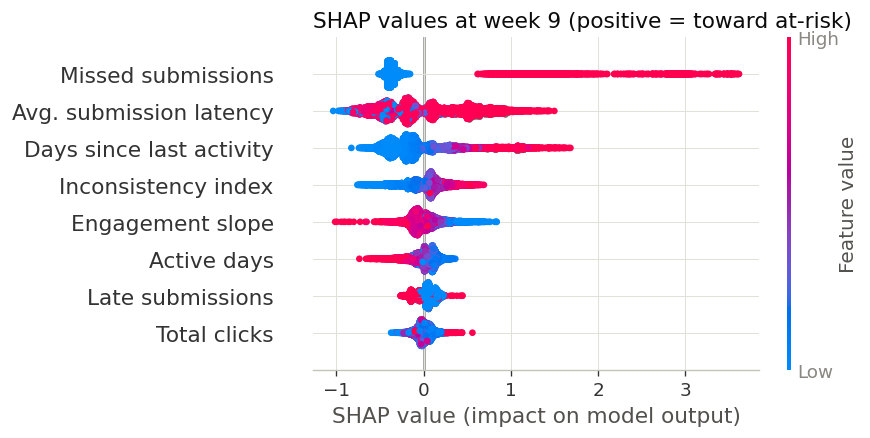

,mean |SHAP| (log-odds)
Missed submissions,0.617
Avg. submission latency,0.411
Days since last activity,0.325
Inconsistency index,0.168
Engagement slope,0.124
Active days,0.107
Late submissions,0.092
Total clicks,0.066


In [13]:
def shap_explanation(week):
    o = store[(week, 'Behavioral', 'XGBoost')]
    ex = shap.TreeExplainer(o['model'])(o['X_test'])
    ex.feature_names = [PRETTY[f] for f in BEHAV]
    return ex

ex = shap_explanation(PRIMARY_WEEK)

# SHAP draws with its own (large) fonts, so these figures are drawn at ~6 in and scale down to column width
plt.figure()
shap.plots.bar(ex, max_display=len(BEHAV), show=False)
plt.gcf().set_size_inches(6, 3.4)
plt.title(f'Mean |SHAP| at week {PRIMARY_WEEK}', loc='left', fontsize=13)
plt.savefig(os.path.join(FIG_DIR, f'fig_shap_bar_week{PRIMARY_WEEK}.png'))
plt.show()

plt.figure()
shap.plots.beeswarm(ex, max_display=len(BEHAV), show=False)
plt.gcf().set_size_inches(6, 3.6)
plt.title(f'SHAP values at week {PRIMARY_WEEK} (positive = toward at-risk)', loc='left', fontsize=13)
plt.savefig(os.path.join(FIG_DIR, f'fig_shap_beeswarm_week{PRIMARY_WEEK}.png'))
plt.show()

mean_abs = pd.Series(np.abs(ex.values).mean(0), index=ex.feature_names).sort_values(ascending=False)
display(mean_abs.round(3).to_frame('mean |SHAP| (log-odds)'))

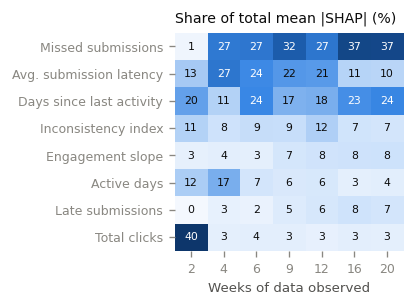

In [14]:
# How the importance of each behavioural marker shifts as more of the course is observed
imp = pd.DataFrame({w: np.abs(shap_explanation(w).values).mean(0) for w in CUTOFF_WEEKS},
                   index=[PRETTY[f] for f in BEHAV])
share = imp / imp.sum(0)
share = share.loc[share[PRIMARY_WEEK].sort_values(ascending=False).index]
share.to_csv(os.path.join(RES_DIR, 'shap_share_by_cutoff.csv'))

ramp = LinearSegmentedColormap.from_list('blue_seq', ['#f4f8fe', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
fig, ax = plt.subplots(figsize=(3.5, 2.6))
im = ax.imshow(share.values, cmap=ramp, vmin=0, vmax=share.values.max(), aspect='auto')
ax.set_xticks(range(len(CUTOFF_WEEKS)), [str(w) for w in CUTOFF_WEEKS])
ax.set_yticks(range(len(share)), share.index)
ax.set_xlabel('Weeks of data observed'); ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        v = share.values[i, j]
        ax.text(j, i, f'{100 * v:.0f}', ha='center', va='center', fontsize=6.5,
                color='white' if v > 0.55 * share.values.max() else INK)
ax.set_title('Share of total mean |SHAP| (%)', loc='left')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'fig_shap_share_by_cutoff.png'))
plt.show()

## 8. Sensitivity analysis: academic failure only

The at-risk label combines two different outcomes (failing and dropping out). Here withdrawals are removed and the
behavioural XGBoost model is re-tuned to separate Fail from Pass/Distinction.

In [15]:
sens, sens_store = [], {}
for w in CUTOFF_WEEKS:
    row, out = run(w, 'Behavioral', 'XGBoost', label_mode='fail_vs_pass')
    idx = rng.integers(0, len(out['y']), size=(N_BOOT, len(out['y'])))
    b = np.array([roc_auc_score(out['y'][i], out['p'][i]) for i in idx])
    row['auc_ci_low'], row['auc_ci_high'] = np.percentile(b, [2.5, 97.5])
    sens.append(row)
sens = pd.DataFrame(sens)
sens.to_csv(os.path.join(RES_DIR, 'sensitivity_fail_vs_pass.csv'), index=False)
display(sens[['cutoff_week', 'n_train', 'n_test', 'cv_auc_mean', 'test_auc', 'auc_ci_low', 'auc_ci_high',
              'precision', 'recall', 'f1']].round(3))

,cutoff_week,n_train,n_test,cv_auc_mean,test_auc,auc_ci_low,auc_ci_high,precision,recall,f1
0,2,14995,7434,0.698,0.690,0.676,0.703,0.358,0.742,0.483
1,4,14995,7434,0.743,0.711,0.697,0.724,0.379,0.698,0.491
2,6,14995,7434,0.767,0.735,0.723,0.747,0.407,0.686,0.511
3,9,14995,7434,0.809,0.775,0.764,0.787,0.479,0.644,0.549
4,12,14995,7434,0.822,0.788,0.776,0.800,0.508,0.635,0.565
5,16,14995,7434,0.859,0.825,0.814,0.836,0.584,0.634,0.608
6,20,14995,7434,0.885,0.848,0.838,0.859,0.704,0.615,0.656


## 9. Summary

In [16]:
p = primary.set_index(['feature_set', 'model'])
x = p.loc[('Behavioral', 'XGBoost')]
dm = p.loc[('Demographic', 'XGBoost')]
print(f"Week {PRIMARY_WEEK} (day {7 * PRIMARY_WEEK - 1}, ~{100 * 7 * PRIMARY_WEEK / mean_len:.0f}% of a presentation), "
      f"temporal test on {TEST_PRES[0]} (n = {int(x.n_test):,}):")
print(f"  Behavioral XGBoost  AUC {x.test_auc:.3f} [{x.auc_ci_low:.3f}, {x.auc_ci_high:.3f}], "
      f"precision {x.precision:.3f}, recall {x.recall:.3f}, F1 {x.f1:.3f}")
print(f"  Demographic XGBoost AUC {dm.test_auc:.3f} [{dm.auc_ci_low:.3f}, {dm.auc_ci_high:.3f}]")
print(f"  Full-course retrospective XGBoost AUC {full_auc:.3f} (upper bound; not an early prediction)")
print(f"  Top SHAP markers: {', '.join(mean_abs.index[:3])}")

Week 9 (day 62, ~25% of a presentation), temporal test on 2014J (n = 8,794):
  Behavioral XGBoost  AUC 0.774 [0.764, 0.784], precision 0.568, recall 0.720, F1 0.635
  Demographic XGBoost AUC 0.626 [0.615, 0.637]
  Full-course retrospective XGBoost AUC 0.968 (upper bound; not an early prediction)
  Top SHAP markers: Missed submissions, Avg. submission latency, Days since last activity
